In [1]:
import pysvorbit
import matplotlib.pyplot as plt
import numpy as np
from backend import _solve_kepler

import contextlib
import io
import backend


In [2]:
# Sky projected orbit plotter function
def get_sky_projected_orbit(a, e, i, omega, Omega, num_points):

    # Computes sky-projected coordinates (X, Y) from Keplerian elements. Angles (i, omega, Omega) should be in degrees.
    
    # Convert angles to radians
    i_rad = np.radians(i)
    omega_rad = np.radians(omega)
    Omega_rad = np.radians(Omega)
    
    # 1. Sample true anomalies across a full orbit
    nu = np.linspace(0, 2 * np.pi, num_points)
    
    # 2. Distance 'r' from the focus for an ellipse
    r = (a * (1 - e**2)) / (1 + e * np.cos(nu))
    
    # Position vectors in the intrinsic orbital plane
    x_prime = r * np.cos(nu)
    y_prime = r * np.sin(nu)
    
    # 3. Apply Thiele-Innes or standard rotation matrix combinations
    # X (East) and Y (North) positions projected on the plane of the sky
    X = x_prime * (np.cos(omega_rad) * np.sin(Omega_rad) + np.sin(omega_rad) * np.cos(Omega_rad) * np.cos(i_rad)) + \
        y_prime * (-np.sin(omega_rad) * np.sin(Omega_rad) + np.cos(omega_rad) * np.cos(Omega_rad) * np.cos(i_rad))
        
    Y = x_prime * (np.cos(omega_rad) * np.cos(Omega_rad) - np.sin(omega_rad) * np.sin(Omega_rad) * np.cos(i_rad)) + \
        y_prime * (-np.sin(omega_rad) * np.cos(Omega_rad) - np.cos(omega_rad) * np.sin(Omega_rad) * np.cos(i_rad))
        
    return X, Y



def sky_position_at_epoch(t, P, T, e, a, i, omega, Omega):
    """
    Model position on the sky at epoch(s) t, using the same projection as
    get_sky_projected_orbit(). 'a' in the units you want back (mas here);
    angles in degrees; t, T, P all in years.
    Returns (North, East) so it plots directly on your (x = North, y = East) axes.
    """
    t = np.atleast_1d(np.asarray(t, dtype=float))
 
    # Mean anomaly at each epoch
    M = 2 * np.pi * (((t - T) / P) % 1.0)
 
    # Eccentric anomaly from PySVOrbit's own Kepler solver (one epoch at a time)
    E = np.array([_solve_kepler(m, e) for m in M])
 
    # Safety check: _solve_kepler can occasionally diverge at very high e
    bad = np.abs(E - e * np.sin(E) - M) > 1e-6
    if bad.any():
        raise RuntimeError(f"_solve_kepler did not converge for epoch(s) {t[bad]}")
 
    # True anomaly and orbital radius
    nu = 2 * np.arctan2(np.sqrt(1 + e) * np.sin(E / 2), np.sqrt(1 - e) * np.cos(E / 2))
    r = a * (1 - e**2) / (1 + e * np.cos(nu))
    xp, yp = r * np.cos(nu), r * np.sin(nu)
 
    io, wo, Oo = np.radians([i, omega, Omega])
    East = xp * (np.cos(wo) * np.sin(Oo) + np.sin(wo) * np.cos(Oo) * np.cos(io)) + \
           yp * (-np.sin(wo) * np.sin(Oo) + np.cos(wo) * np.cos(Oo) * np.cos(io))
    North = xp * (np.cos(wo) * np.cos(Oo) - np.sin(wo) * np.sin(Oo) * np.cos(io)) + \
            yp * (-np.sin(wo) * np.cos(Oo) - np.cos(wo) * np.sin(Oo) * np.cos(io))
    return North, East


In [3]:
# Sampling points for get_sky_projected_orbit function
num_points = 5000

In [4]:
target = "GJ 586Aab (HD 137763, WDS 15282-0921)"
unit = 'mas' 

In [5]:
# Load observation points for SOAR data

data = np.genfromtxt("Obs Point Plotting CSVs/GJ586A_2016Tokovinin.csv", delimiter=",", skip_header=1, usecols = (0, 1, 2))
theta_obs_soar = np.deg2rad(data[:, 0])   # position angle, N through E
rho_obs = data[:, 1]                 # separation (arcsec)

t_obs2016 = data[:, 2]                   # epoch (decimal year)
x_obs2016 = rho_obs * np.cos(theta_obs_soar) * 1000
y_obs2016 = rho_obs * np.sin(theta_obs_soar) * 1000

In [6]:
# Load observation points from PMOIRED MIRC for plotting
data_mirc = np.genfromtxt("Obs Point Plotting CSVs/GJ586A_MIRC.csv", delimiter=",", skip_header=1, usecols=(0, 1, 2))
theta_obs_mirc = np.deg2rad(data_mirc[:, 0])  # position angle, N through E
rho_obs_mirc = data_mirc[:, 1]                # separation (mas)
t_obs_mirc = data_mirc[:, 2]

x_obs_mirc = rho_obs_mirc * np.cos(theta_obs_mirc)
y_obs_mirc = rho_obs_mirc * np.sin(theta_obs_mirc)


In [7]:
# Monte Carlo refits. Each trial perturbs the position measurements by
# their uncertainties and refits the orbit, so the elements vary together.
# The radial velocities are left unchanged. The plotted curve depends on
# a, e, i, w, and W.


def fitorb_MC(N_orbits, seed=42, outfile=None):
    """Refit the orbit N_orbits times and return the kept results.

    Positions are perturbed by their uncertainties. Radial velocities are
    left unchanged. Unbound refits (a <= 0 or e outside [0, 1)) are dropped.
    The returned east/north tracks are plain lists, so they survive a later
    readinp() of a different file. Draw them in a later cell.

    Returns
    -------
    elements : dict of lists
        One Python list per orbital element (P, T, e, a, W, w, i)
        and per mass (Astrometric_Total_Mass_Msun, Spectroscopic_Total_Mass_Msun,
        M12_sin3i, M1, M2).
        Each list has one value per kept refit.
    east : list of lists
        East coordinate, in mas, of each kept orbit.
    north : list of lists
        North coordinate, in mas, of each kept orbit.
    mc : dict
        For each of P, T, e, a, W, w, and i: median, err_lo, and err_hi.
        The same three numbers are stored for Astrometric_Total_Mass_Msun,
        Spectroscopic_Total_Mass_Msun, M12_sin3i, M1, and M2.
        err_lo and err_hi are the distances from the median to the
        15.87 and 84.13 percentiles.
    """
    rng = np.random.default_rng(seed)

    # Copies of the real fit. Positions are noised each trial; the radial
    # velocities and the starting elements are put back unchanged.
    pos0 = pysvorbit.orb.pos.copy()
    rv1_0 = pysvorbit.orb.rv1.copy()
    rv2_0 = pysvorbit.orb.rv2.copy()
    el0 = pysvorbit.orb.el.copy()
    elerr0 = pysvorbit.orb.elerr.copy()
    names = list(pysvorbit.orb.elname)
    fitted = []
    n_fail = 0

    # fitorb() draws an orbit plot on every call. Turn that off for the loop.
    orig_orbplot = backend.orbplot
    backend.orbplot = lambda *args, **kwargs: None

    progress = 0
    try:
        for trial in range(N_orbits):
            # Start this trial from the original measurements and best-fit elements.
            pysvorbit.orb.pos = pos0.copy()
            pysvorbit.orb.rv1 = rv1_0.copy()
            pysvorbit.orb.rv2 = rv2_0.copy()
            pysvorbit.orb.el = el0.copy()

            # Add a Gaussian draw of each position's own uncertainty.
            # Column 1 is position angle, column 2 is separation, and column 3
            # is the separation uncertainty. The angle error is that separation
            # error converted to degrees. Separations are kept positive.
            rho = pos0[:, 2]
            sig_rho = pos0[:, 3]
            sig_pa = sig_rho * 180 / np.pi / rho
            pysvorbit.orb.pos[:, 1] = pos0[:, 1] + rng.normal(0, sig_pa)
            pysvorbit.orb.pos[:, 2] = np.maximum(rho + rng.normal(0, sig_rho), 1e-6)

            # Refit. A trial fails if fitorb() raises, or if any element comes
            # back NaN or infinite. Finite refits are stored as one row so the
            # elements from that trial stay together.
            try:
                with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                    pysvorbit.fitorb()
                row = pysvorbit.orb.el.copy()
                if not np.all(np.isfinite(row)):
                    n_fail += 1
                    continue
                fitted.append(row)
            except Exception:
                n_fail += 1
                continue
            finally:
                plt.close("all")

            # Progress every trial, plus a shorter summary every 25 trials.
            print(f"{trial+1}/{N_orbits}; {n_fail} Failed")
    finally:
        # Always put the plot function, the data, and the best fit back.
        backend.orbplot = orig_orbplot
        pysvorbit.orb.pos = pos0
        pysvorbit.orb.rv1 = rv1_0
        pysvorbit.orb.rv2 = rv2_0
        pysvorbit.orb.el = el0.copy()
        pysvorbit.orb.elerr = elerr0.copy()

    if not fitted:
        raise RuntimeError("Every Monte Carlo refit failed")

    # One column per element, taken from the successful refits.
    fitted = np.vstack(fitted)
    samples = {name: fitted[:, names.index(name)] for name in names}

    # Drop unbound or non-physical orbits. This is separate from n_fail:
    # those refits returned finite elements, they just are not plotted.
    keep = (
        (samples["a"] > 0)
        & (samples["e"] >= 0)
        & (samples["e"] < 1)
        & np.isfinite(samples["a"])
        & np.isfinite(samples["e"])
    )
    for key in samples:
        samples[key] = samples[key][keep]
    n_kept = int(samples["a"].size)
    
    
    
    
    
    
    
    (f"Drew {N_orbits} refits, kept {n_kept} with a > 0 and 0 <= e < 1, failed {n_fail}")

    # 1-sigma interval of the kept refits: median, and the 15.87/84.13 percentiles.
    # Printed for the orbital elements only. K1, K2, and V0 stay out of this table.
    fit_value = {name: el0[names.index(name)] for name in names}
    fit_error = {name: elerr0[names.index(name)] for name in names}
    mc_median = {}
    mc_err_lo = {}
    mc_err_hi = {}
    orbital_names = [name for name in ("P", "T", "e", "a", "W", "w", "i") if name in names]
    print("\nMonte Carlo orbital elements (refits)")
    lines = ["Monte Carlo orbital elements (refits)"]
    for name in orbital_names:
        lo, med, hi = np.percentile(samples[name], [15.87, 50.0, 84.13])
        mc_median[name] = med
        mc_err_lo[name] = med - lo
        mc_err_hi[name] = hi - med
        line = (
            f"{name} = {np.format_float_positional(med, unique=True, trim='k')}  "
            f"+{np.format_float_positional(mc_err_hi[name], unique=True, trim='k')} / "
            f"-{np.format_float_positional(mc_err_lo[name], unique=True, trim='k')}"
            f"    fit {np.format_float_positional(fit_value[name], unique=True, trim='k')} "
            f"\u00b1 {np.format_float_positional(fit_error[name], unique=True, trim='k')}"
        )
        print(line)
        lines.append(line)

    # Masses of each kept refit. Parallax is the input-file value and is
    # not perturbed. Astrometric_Total_Mass_Msun comes from calculate_total_mass.
    # Spectroscopic_Total_Mass_Msun is M1 + M2 from calculate_spectroscopic_masses.
    plx = float(pysvorbit.orb.obj["parallax"])
    n = n_kept
    M_ast = np.empty(n)
    M12_sin3i = np.empty(n)
    M1 = np.empty(n)
    M2 = np.empty(n)
    for k in range(n):
        M_ast[k] = pysvorbit.calculate_total_mass(
            samples["P"][k], samples["a"][k], plx
        )
        M12_sin3i[k], M1[k], M2[k] = pysvorbit.calculate_spectroscopic_masses(
            samples["P"][k],
            samples["e"][k],
            samples["i"][k],
            samples["K1"][k],
            samples["K2"][k],
        )
    samples["Astrometric_Total_Mass_Msun"] = M_ast
    samples["Spectroscopic_Total_Mass_Msun"] = M1 + M2
    samples["M12_sin3i"] = M12_sin3i
    samples["M1"] = M1
    samples["M2"] = M2
    fit_value["Astrometric_Total_Mass_Msun"] = pysvorbit.calculate_total_mass(
        fit_value["P"], fit_value["a"], plx
    )
    (
        fit_value["M12_sin3i"],
        fit_value["M1"],
        fit_value["M2"],
    ) = pysvorbit.calculate_spectroscopic_masses(
        fit_value["P"], fit_value["e"], fit_value["i"], fit_value["K1"], fit_value["K2"]
    )
    fit_value["Spectroscopic_Total_Mass_Msun"] = fit_value["M1"] + fit_value["M2"]
    mass_names = [
        "Astrometric_Total_Mass_Msun",
        "Spectroscopic_Total_Mass_Msun",
        "M12_sin3i",
        "M1",
        "M2",
    ]
    plx_line = (
        "parallax = "
        + np.format_float_positional(plx, unique=True, trim="k")
        + " mas (fixed)"
    )
    print("\nMonte Carlo masses (solar masses)")
    print(plx_line)
    lines.append("")
    lines.append("Monte Carlo masses (solar masses)")
    lines.append(plx_line)
    for name in mass_names:
        finite = np.isfinite(samples[name])
        lo, med, hi = np.percentile(samples[name][finite], [15.87, 50.0, 84.13])
        mc_median[name] = med
        mc_err_lo[name] = med - lo
        mc_err_hi[name] = hi - med
        line = (
            f"{name} = {np.format_float_positional(med, unique=True, trim='k')}  "
            f"+{np.format_float_positional(mc_err_hi[name], unique=True, trim='k')} / "
            f"-{np.format_float_positional(mc_err_lo[name], unique=True, trim='k')}"
            f"    fit {np.format_float_positional(fit_value[name], unique=True, trim='k')}"
        )
        print(line)
        lines.append(line)
    if outfile is not None:
        with open(outfile, "w") as fh:
            fh.write("\n".join(lines) + "\n")
        print(f"Wrote {outfile}")

    # Project each kept orbit onto the sky. a is in arcseconds in the fit
    # and is converted to milliarcseconds here.
    East = np.empty((n_kept, num_points))
    North = np.empty((n_kept, num_points))
    for k in range(n_kept):
        East[k], North[k] = get_sky_projected_orbit(
            samples["a"][k] * 1e3,
            samples["e"][k],
            samples["i"][k],
            samples["w"][k],
            samples["W"][k],
            num_points,
        )

    # One list per orbital element, and one east/north track per kept orbit.
    summary_names = orbital_names + mass_names
    elements = {name: samples[name].tolist() for name in summary_names}
    mc = {
        name: {
            "median": float(mc_median[name]),
            "err_lo": float(mc_err_lo[name]),
            "err_hi": float(mc_err_hi[name]),
        }
        for name in summary_names
    }
    return elements, East.tolist(), North.tolist(), mc





Position measures: 10
RV measures: 714, 615
Fitting 10 elements: ['P', 'T', 'e', 'a', 'W', 'w', 'i', 'K1', 'K2', 'V0']
Total observations: 1349 (npos=10, nrv1=714, nrv2=615)
`xtol` termination condition is satisfied.
Function evaluations 6, initial cost 5.0872e+06, final cost 2.1128e+06, first-order optimality 1.31e+03.
Degrees of freedom: 1339
Chi-squared: 4225622.8798, Reduced Chi-squared: 3155.8050
Jacobian shape: (1349, 10)
JTJ condition number: 6.22e+13
Covariance matrix computed successfully (not rescaled by reduced chi-square)
CHI2/N: ['2.0991', '27.3262', '5878.5662', '45.5810']
RMS (Theta, rho, RV1, RV2): 0.0818, 0.0001, 0.4319, 0.2454

Initial Parameters (from input file):
P    :     2.4362
T    :  2007.2597
e    :     0.9761
a    :     0.1074
W    :   272.8000
w    :   255.6900
i    :    55.4000

Initial Mass Estimates:
 Total mass (from a, P, π): 1.560 solar masses

Initial Spectroscopic Mass Estimates:
  M(1+2)·sin³i   = 0.797844 solar masses
  M₁             = 0.857306 so

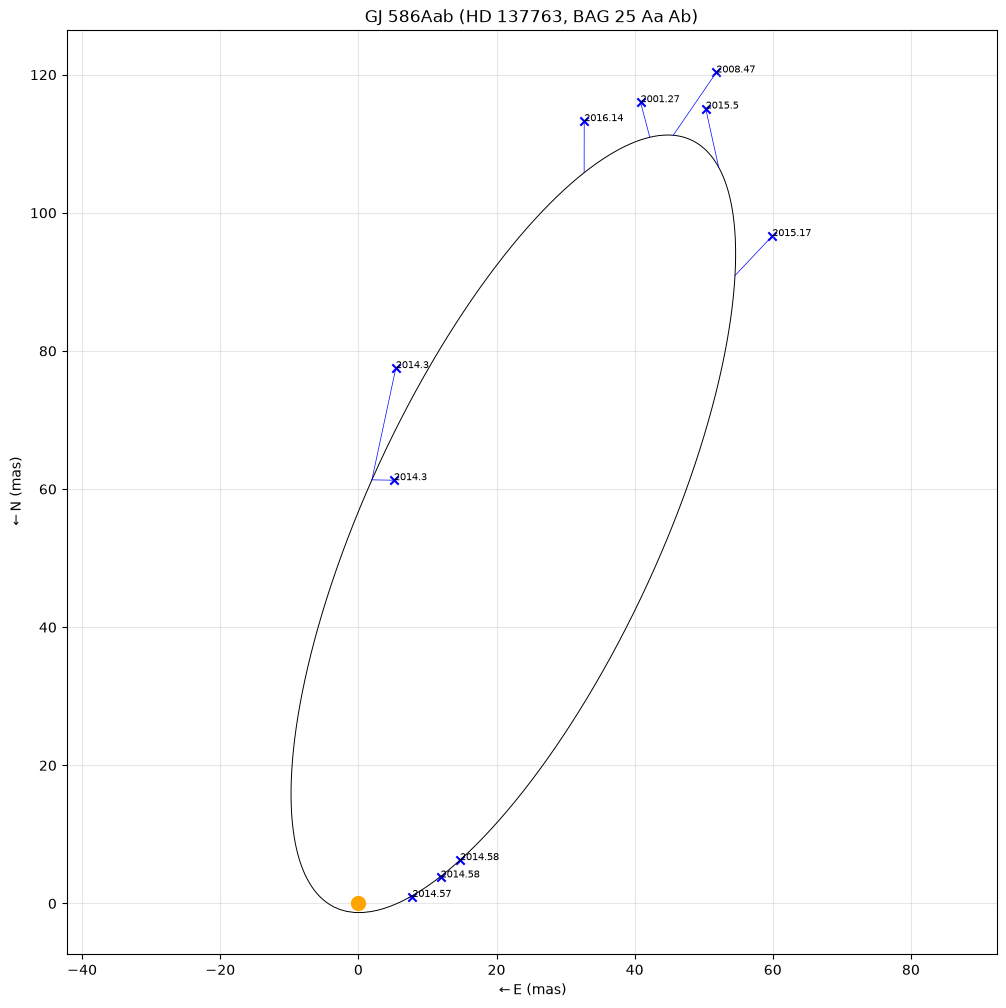

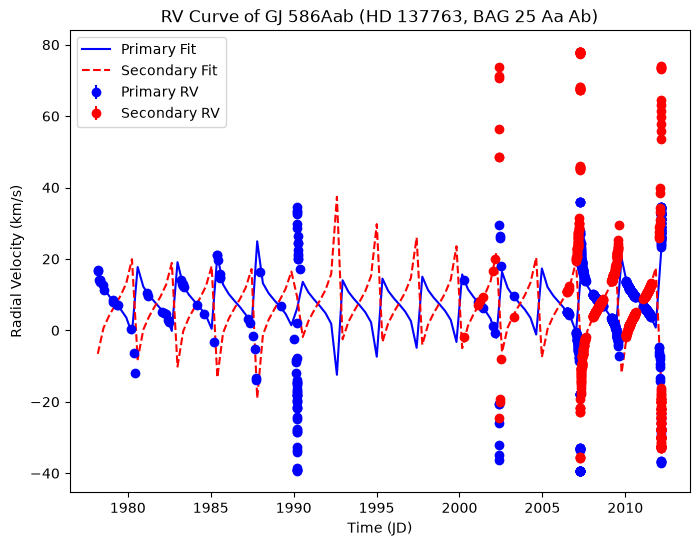

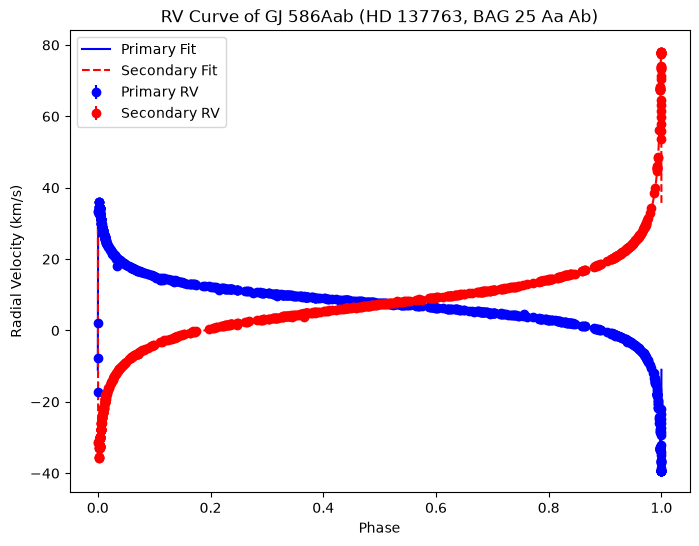

In [8]:
# Load and fit the MIRC file. fitorb_MC perturbs whatever orbit is loaded.
data_path = "SOAR + MIRC + Strass2013RV/GJ586A_SOAR_MIRC_StrassRV.inp"
pysvorbit.readinp(data_path)

pos_mirc = pysvorbit.orb.pos          # one row per position measurement
t_obs_test = pos_mirc[:, 0]            # epochs of the SOAR and MIRC positions in this file
x_obs_test = pos_mirc[:, 2] * np.cos(np.deg2rad(pos_mirc[:, 1])) * 1000
y_obs_test = pos_mirc[:, 2] * np.sin(np.deg2rad(pos_mirc[:, 1])) * 1000

orig_orbplot = backend.orbplot
backend.orbplot = lambda *args, **kwargs: None
try:
    pysvorbit.fitorb()
    pysvorbit.orbplot(ps=True)
finally:
    backend.orbplot = orig_orbplot
    

P, T, e, a, W, w, i, K1, K2, V0 = pysvorbit.orb.el
P_err, T_err, e_err, a_err, W_err, w_err, i_err, K1_err, K2_err, V0_err = pysvorbit.orb.elerr
X_test, Y_test = get_sky_projected_orbit(a * 1e3, e, i, w, W, num_points)


In [9]:
plt.close("all")

In [10]:
# MC on the MIRC + SOAR + Strassmeier RV

N_orbits = 500
mc_elements_mirc, East, North, mc_mirc = fitorb_MC(
    N_orbits, outfile=f"MC_MIRC_SOAR_StrassRV_elements_{N_orbits}.txt"
)
n_kept = len(East)

1/500; 0 Failed
2/500; 0 Failed
3/500; 0 Failed
4/500; 0 Failed
5/500; 0 Failed
6/500; 0 Failed
7/500; 0 Failed
8/500; 0 Failed
9/500; 0 Failed
10/500; 0 Failed
11/500; 0 Failed
12/500; 0 Failed
13/500; 0 Failed
14/500; 0 Failed
15/500; 0 Failed
16/500; 0 Failed
17/500; 0 Failed
18/500; 0 Failed
19/500; 0 Failed
20/500; 0 Failed
21/500; 0 Failed
22/500; 0 Failed
23/500; 0 Failed
24/500; 0 Failed
25/500; 0 Failed
26/500; 0 Failed
27/500; 0 Failed
28/500; 0 Failed
29/500; 0 Failed
30/500; 0 Failed
31/500; 0 Failed
32/500; 0 Failed
33/500; 0 Failed
34/500; 0 Failed
35/500; 0 Failed
36/500; 0 Failed
37/500; 0 Failed
38/500; 0 Failed
39/500; 0 Failed
40/500; 0 Failed
41/500; 0 Failed
42/500; 0 Failed
43/500; 0 Failed
44/500; 0 Failed
45/500; 0 Failed
46/500; 0 Failed
47/500; 0 Failed
48/500; 0 Failed
49/500; 0 Failed
50/500; 0 Failed
51/500; 0 Failed
52/500; 0 Failed
53/500; 0 Failed
54/500; 0 Failed
55/500; 0 Failed
56/500; 0 Failed
57/500; 0 Failed
58/500; 0 Failed
59/500; 0 Failed
60/500

In [11]:
# MC on the SOAR + Strassmeier RV, have to reload file since PySVOrbit only keeps one loaded

# The MIRC Monte Carlo is already in East and North from the cell above.
# This cell only refits GJ586A_SOAR_StrassRV.inp. readinp() replaces the
# orbit PySVOrbit holds, but the MIRC tracks are already copied out.
soar_path = "SOAR + Strass2013RV/GJ586A_SOAR_StrassRV.inp"
mirc_path = "SOAR + MIRC + Strass2013RV/GJ586A_SOAR_MIRC_StrassRV.inp"

def mc_one_file(path, N_orbits, seed=42, outfile=None):
    print(f"\n===== {path} =====")
    pysvorbit.readinp(path)

    # One best fit first. The Monte Carlo starts from these elements, and
    # fitorb() would otherwise open an orbit figure on this call.
    orig_orbplot = backend.orbplot
    backend.orbplot = lambda *args, **kwargs: None
    try:
        pysvorbit.fitorb()
    finally:
        backend.orbplot = orig_orbplot
        plt.close("all")

    elements, east, north, mc = fitorb_MC(N_orbits=N_orbits, seed=seed, outfile=outfile)

    # Project this file's best fit now. The next readinp() replaces orb.el.
    names = list(pysvorbit.orb.elname)
    el = pysvorbit.orb.el
    X, Y = get_sky_projected_orbit(
        el[names.index("a")] * 1e3,
        el[names.index("e")],
        el[names.index("i")],
        el[names.index("w")],
        el[names.index("W")],
        num_points,
    )
    return {"elements": elements, "east": east, "north": north, "X": X, "Y": Y, "mc": mc}

mc_soar = mc_one_file(soar_path, N_orbits, outfile=f"MC_SOAR_StrassRV_elements_{N_orbits}.txt")
mc_fits = {
    "MIRC + SOAR + Strassmeier RV": mc_mirc,
    "SOAR + Strassmeier RV": mc_soar["mc"],
}

# fitorb_MC puts the SOAR best fit back. Copy it before the MIRC file is loaded.
P_soar, T_soar, e_soar, a_soar, W_soar, w_soar, i_soar, K1_soar, K2_soar, V0_soar = pysvorbit.orb.el
P_soar_err, T_soar_err, e_soar_err, a_soar_err, W_soar_err, w_soar_err, i_soar_err, K1_soar_err, K2_soar_err, V0_soar_err = pysvorbit.orb.elerr

# One fit of the MIRC file, not another Monte Carlo, so later cells still
# see that orbit. Its Monte Carlo curves stay the ones already in East, North.
data_path = mirc_path
pysvorbit.readinp(data_path)
orig_orbplot = backend.orbplot
backend.orbplot = lambda *args, **kwargs: None
try:
    pysvorbit.fitorb()
    pysvorbit.orbplot(ps=True)
finally:
    backend.orbplot = orig_orbplot
    plt.close("all")



===== SOAR + Strass2013RV/GJ586A_SOAR_StrassRV.inp =====
Position measures: 7
RV measures: 714, 615
Fitting 10 elements: ['P', 'T', 'e', 'a', 'W', 'w', 'i', 'K1', 'K2', 'V0']
Total observations: 1343 (npos=7, nrv1=714, nrv2=615)
`xtol` termination condition is satisfied.
Function evaluations 6, initial cost 5.0846e+06, final cost 2.1127e+06, first-order optimality 1.31e+03.
Degrees of freedom: 1333
Chi-squared: 4225336.7262, Reduced Chi-squared: 3169.7950
Jacobian shape: (1343, 10)
JTJ condition number: 5.11e+15
Error computing covariance: normal matrix is effectively singular (condition number 5.11e+15)
Using approximate unscaled errors
CHI2/N: ['0.8202', '0.3351', '5878.5680', '45.5790']
RMS (Theta, rho, RV1, RV2): 1.3379, 0.0017, 0.4319, 0.2454

Initial Parameters (from input file):
P    :     2.4362
T    :  2007.2597
e    :     0.9761
a    :     0.1074
W    :   272.8000
w    :   255.6900
i    :    55.4000

Initial Mass Estimates:
 Total mass (from a, P, π): 1.560 solar masses

Ini

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


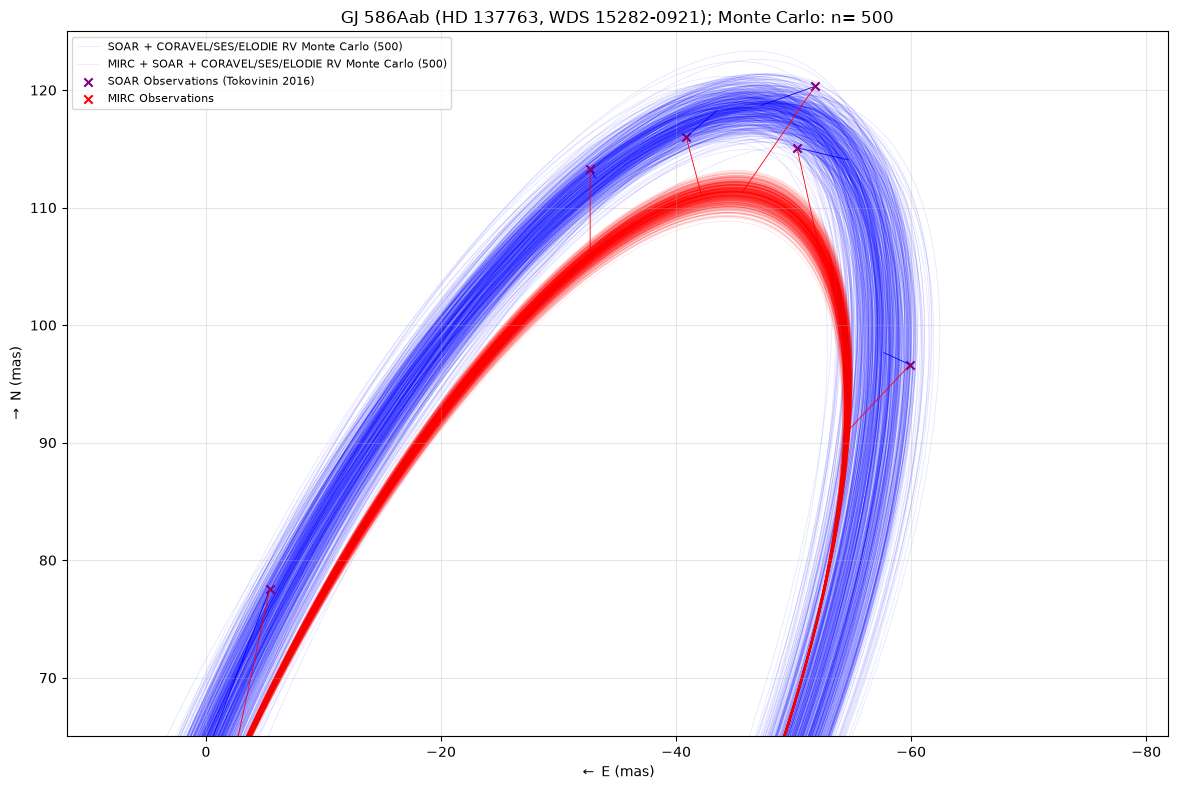

In [ ]:
# SOAR Monte Carlo from mc_soar, MIRC Monte Carlo from East and North.
fig, ax = plt.subplots(figsize=(12, 8))

MC_opacity = 0.1
# 0.05 for Full view
# 0.15 for Periastron
# 0.10 for Apastron

# Plot SOAR + Strassmeier RV Data MC Orbits
for k, (east, north) in enumerate(zip(mc_soar["east"], mc_soar["north"])):
    ax.plot(east, north, color="blue", lw=0.6, alpha=MC_opacity, zorder=1,
            label=f"SOAR + CORAVEL/SES/ELODIE RV Monte Carlo ({len(mc_soar['east'])})" if k == 0 else None)
# Plot SOAR + Strassmeier RV Data Best Fit
# ax.plot(mc_soar["X"], mc_soar["Y"], color="orange", lw=1.0, zorder=2,
#         label="SOAR + CORAVEL/SES/ELODIE RV Best Fit")



# Plot MIRC + SOAR + Strassmeier RV Data MC Orbits
for k, (east, north) in enumerate(zip(East, North)):
    ax.plot(east, north, color="red", lw=0.6, alpha=MC_opacity, zorder=1,
            label=f"MIRC + SOAR + CORAVEL/SES/ELODIE RV Monte Carlo ({len(East)})" if k == 0 else None)
# Plot MIRC + SOAR + Strassmeier RV Data Best Fit
# ax.plot(X_test, Y_test, color="black", lw=1.0, zorder=2,
#         label="MIRC + SOAR + CORAVEL/SES/ELODIE RV Best Fit")



# Plot the SOAR + Strassmeier RV observations and their residuals to the SOAR + Strassmeier RV fit.
ax.scatter(y_obs2016, x_obs2016, label="SOAR Observations (Tokovinin 2016)", marker="x", color="purple", zorder=2)
# Plot Residual Lines
N_mod_soar, E_mod_soar = sky_position_at_epoch(
    t_obs2016, P_soar, T_soar, e_soar, a_soar * 1e3, i_soar, w_soar, W_soar)
for xo, yo, xm, ym in zip(x_obs2016, y_obs2016, N_mod_soar, E_mod_soar):
    ax.plot([yo, ym], [xo, xm], linestyle="-", color="blue", lw=0.6, zorder=2)


# Plot the MIRC + SOAR + Strassmeier RV observations and their residuals to the MIRC + SOAR + Strassmeier RV fit.
ax.scatter(y_obs_mirc, x_obs_mirc, marker="x", color="red", label="MIRC Observations", zorder=2)
# Plot Residual Lines
N_modtest, E_modtest = sky_position_at_epoch(t_obs_test, P, T, e, a * 1e3, i, w, W)
for xo, yo, xm, ym in zip(x_obs_test, y_obs_test,N_modtest, E_modtest):
    ax.plot([yo, ym], [xo, xm], linestyle="-", color="red", lw=0.6, zorder=2)

ax.add_patch(plt.Circle((0, 0), 1, facecolor="orange"))

ax.set_aspect("equal", adjustable="datalim")
ax.invert_xaxis()  # East to the left


# For Apastron Passage zoom-in:
centerx = -35
centery = 95
half_width = 30

"""
# For Periastron Passage zoom-in
centerx = 0
centery = 7.5
half_width = 10
"""
ax.set_xlim(centerx+half_width, centerx-half_width)
ax.set_ylim(centery-half_width, centery+half_width)

ax.grid(alpha=0.3)
ax.set_xlabel(r"$\leftarrow$ E (mas)")
ax.set_ylabel(r"$\rightarrow$ N (mas)")
ax.set_title(f"{target}; Monte Carlo: n= {N_orbits}")
ax.legend(fontsize=8, loc="upper left")

fig.tight_layout()

fig.savefig(f"MC_MIRC({len(t_obs_mirc)})_SOAR({len(t_obs2016)})_StrassRV_{N_orbits}.png")

plt.show()


In [13]:
mirc_names = ["P", "T", "e", "a", "W", "w", "i", "K1", "K2", "V0"]
mirc_values = [P, T, e, a, W, w, i, K1, K2, V0]
mirc_errors = [P_err, T_err, e_err, a_err, W_err, w_err, i_err, K1_err, K2_err, V0_err]
soar_values = [P_soar, T_soar, e_soar, a_soar, W_soar, w_soar, i_soar, K1_soar, K2_soar, V0_soar]
soar_errors = [P_soar_err, T_soar_err, e_soar_err, a_soar_err, W_soar_err, w_soar_err, i_soar_err, K1_soar_err, K2_soar_err, V0_soar_err]

print("\nMIRC + SOAR + Strassmeier RV")
for name, value, error in zip(mirc_names, mirc_values, mirc_errors):
    print(f"{name} = {np.format_float_positional(value, unique=True, trim='k')} \u00b1 {np.format_float_positional(error, unique=True, trim='k')}")

print("\nSOAR + Strassmeier RV")
for name, value, error in zip(mirc_names, soar_values, soar_errors):
    print(f"{name} = {np.format_float_positional(value, unique=True, trim='k')} \u00b1 {np.format_float_positional(error, unique=True, trim='k')}")



MIRC + SOAR + Strassmeier RV
P = 2.436346574441253 ± 0.00000011958862518726637
T = 2007.2595968745275 ± 0.0000002617560662566683
e = 0.9768045394974108 ± 0.000001911328479455789
a = 0.10794438042962459 ± 0.00011948639102681112
W = 273.74971784024297 ± 0.17488833646758856
w = 255.73507088141525 ± 0.0016286667002643025
i = 58.5067621299462 ± 0.34541775093568633
K1 = 37.85915556837117 ± 0.0009654480488005947
K2 = 57.08698953165921 ± 0.004886448299665635
V0 = 7.432899087329359 ± 0.00022790994834999935

SOAR + Strassmeier RV
P = 2.4363465775759714 ± 0.9782285731627867
T = 2007.259596875814 ± 0.6689970053348829
e = 0.9768044159277806 ± 0.02359558658737887
a = 0.11933171061823448 ± 0.000000004748892597767996
W = 275.46654216130105 ± 0.000000000007586949270206355
w = 255.7349805993806 ± 0.00009423135345084073
i = 60.18182811267908 ± 0.00000000019557344905461506
K1 = 37.859096101997 ± 0.00013479067656549273
K2 = 57.08689811048508 ± 0.00000023584143383124932
V0 = 7.432899851366187 ± 0.000106544